<div align="center">

# МГТУ им. Н.Э. Баумана

### Факультет «Информатика и системы управления» (ИУ)
### Кафедра «Информационные системы и телекоммуникации» (ИУ3)

# Отчёт по лабораторной работе №2
## по курсу «Технологии машинного обучения»

### Тема: Обработка пропусков в данных, кодирование категориальных признаков, масштабирование данных

</div>

---

**Выполнил:** Суржиков Лев Алексеевич

**Группа:** ИУ3С-51Б

**Проверил:** Ю.Е. Гапанюк

---


## 1. Описание задания

**Цель работы:** изучение способов предварительной обработки данных для дальнейшего формирования моделей.

**Задание:**
1. Выбрать набор данных (датасет), содержащий категориальные признаки и пропуски в данных.
2. Для выбранного датасета на основе материалов лекции решить следующие задачи:
    - обработку пропусков в данных;
    - кодирование категориальных признаков;
    - масштабирование данных.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder
from sklearn.preprocessing import MinMaxScaler, StandardScaler, Normalizer

matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["axes.unicode_minus"] = False

# палитра как в ЛР1: синий - исходные данные, красный - после обработки
BLUE_DARK = "#1B3B6F"
BLUE = "#3B6EA5"
BLUE_LIGHT = "#8FB8D9"
RED_DARK = "#7A1F2B"
RED = "#B23A48"
RED_LIGHT = "#E0949C"


## 2. Описание набора данных

Для работы выбран финансовый датасет **Loan Prediction Problem Dataset** (соревнование Analytics Vidhya, есть на Kaggle: https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset). В нём собраны заявки клиентов жилищной финансовой компании на получение кредита. По анкетным данным клиента нужно предсказать, одобрят ли ему кредит.

Используется файл `train.csv` — 614 заявок, 13 столбцов:

| Признак | Описание | Тип |
|---|---|---|
| `Loan_ID` | номер заявки | идентификатор |
| `Gender` | пол заявителя (Male / Female) | категориальный |
| `Married` | состоит ли в браке (Yes / No) | категориальный |
| `Dependents` | число иждивенцев (0, 1, 2, 3+) | категориальный (порядковый) |
| `Education` | образование (Graduate / Not Graduate) | категориальный |
| `Self_Employed` | самозанятый / ИП (Yes / No) | категориальный |
| `ApplicantIncome` | доход заявителя в месяц | числовой |
| `CoapplicantIncome` | доход созаёмщика в месяц | числовой |
| `LoanAmount` | сумма кредита, тыс. | числовой |
| `Loan_Amount_Term` | срок кредита, мес. | числовой |
| `Credit_History` | кредитная история соответствует требованиям (1 / 0) | бинарный |
| `Property_Area` | где находится недвижимость (Urban / Semiurban / Rural) | категориальный |
| `Loan_Status` | кредит одобрен (Y / N) — целевой признак | категориальный |

Датасет подходит под задание: в нём есть и пропуски, и категориальные признаки.


In [2]:
df = pd.read_csv("loan_prediction.csv")
df.head(10)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


In [3]:
print("Размер датасета:", df.shape)
df.info()


Размер датасета: (614, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


## 3. Обработка пропусков в данных

### 3.1. Поиск пропусков


In [4]:
# количество и процент пропусков по каждому столбцу
missing = pd.DataFrame({
    "Пропусков": df.isnull().sum(),
    "Процент, %": (df.isnull().mean() * 100).round(2),
    "Тип": df.dtypes,
})
missing[missing["Пропусков"] > 0].sort_values("Пропусков", ascending=False)


,Пропусков,"Процент, %",Тип
Credit_History,50,8.14,float64
Self_Employed,32,5.21,object
LoanAmount,22,3.58,float64
Dependents,15,2.44,object
Loan_Amount_Term,14,2.28,float64
Gender,13,2.12,object
Married,3,0.49,object


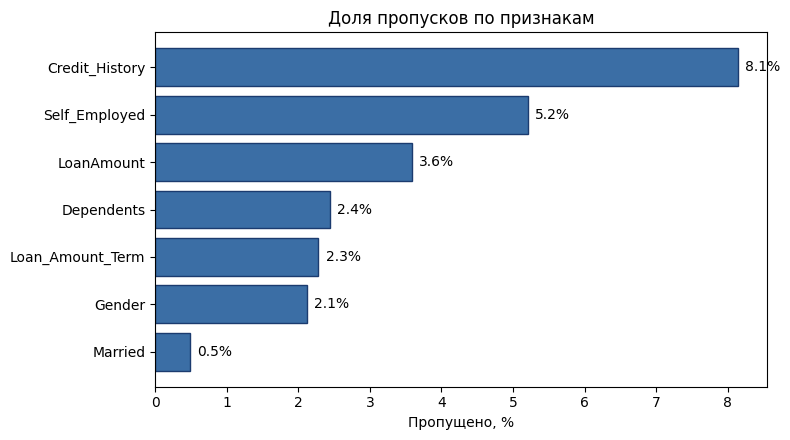

In [5]:
miss = df.isnull().mean().sort_values() * 100
miss = miss[miss > 0]

plt.figure(figsize=(8, 4.5))
plt.barh(miss.index, miss.values, color=BLUE, edgecolor=BLUE_DARK)
for i, v in enumerate(miss.values):
    plt.text(v + 0.1, i, f"{v:.1f}%", va="center")
plt.title("Доля пропусков по признакам")
plt.xlabel("Пропущено, %")
plt.tight_layout()
plt.show()


In [6]:
# разделим столбцы с пропусками на числовые и категориальные
num_cols_na = [c for c in df.columns if df[c].isnull().sum() > 0 and df[c].dtype != "object"]
cat_cols_na = [c for c in df.columns if df[c].isnull().sum() > 0 and df[c].dtype == "object"]
print("Числовые с пропусками:", num_cols_na)
print("Категориальные с пропусками:", cat_cols_na)


Числовые с пропусками: ['LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Категориальные с пропусками: ['Gender', 'Married', 'Dependents', 'Self_Employed']


### 3.2. Удаление строк и столбцов с пропусками

Самый простой способ — удалить строки или столбцы, где есть пропуски. Посмотрим, сколько данных при этом теряется.


In [7]:
df_drop_rows = df.dropna(axis=0, how="any")
df_drop_cols = df.dropna(axis=1, how="any")

print("Исходный датасет:", df.shape)
print("Удалены строки с пропусками:", df_drop_rows.shape,
      f"- потеряно {df.shape[0] - df_drop_rows.shape[0]} строк "
      f"({(1 - df_drop_rows.shape[0] / df.shape[0]) * 100:.1f}%)")
print("Удалены столбцы с пропусками:", df_drop_cols.shape,
      f"- осталось столбцов: {list(df_drop_cols.columns)}")


Исходный датасет: (614, 13)
Удалены строки с пропусками: (480, 13) - потеряно 134 строк (21.8%)
Удалены столбцы с пропусками: (614, 6) - осталось столбцов: ['Loan_ID', 'Education', 'ApplicantIncome', 'CoapplicantIncome', 'Property_Area', 'Loan_Status']


При удалении строк теряется почти 22% заявок, а при удалении столбцов пропадают важные признаки (сумма кредита, кредитная история). Поэтому лучше заполнять пропуски (импьютация).

### 3.3. Заполнение пропусков в числовых признаках

Рассмотрим признак `LoanAmount` (сумма кредита) и сравним заполнение нулями, средним и медианой.


In [8]:
print("Среднее LoanAmount:", round(df["LoanAmount"].mean(), 2))
print("Медиана LoanAmount:", df["LoanAmount"].median())

loan_zero = df["LoanAmount"].fillna(0)
loan_mean = df["LoanAmount"].fillna(df["LoanAmount"].mean())
loan_median = df["LoanAmount"].fillna(df["LoanAmount"].median())

pd.DataFrame({
    "Исходный": df["LoanAmount"].describe(),
    "Нулями": loan_zero.describe(),
    "Средним": loan_mean.describe(),
    "Медианой": loan_median.describe(),
}).round(2)


Среднее LoanAmount: 146.41
Медиана LoanAmount: 128.0


,Исходный,Нулями,Средним,Медианой
count,592.00,614.00,614.00,614.00
mean,146.41,141.17,146.41,145.75
std,85.59,88.34,84.04,84.11
min,9.00,0.00,9.00,9.00
25%,100.00,98.00,100.25,100.25
50%,128.00,125.00,129.00,128.00
75%,168.00,164.75,164.75,164.75
max,700.00,700.00,700.00,700.00


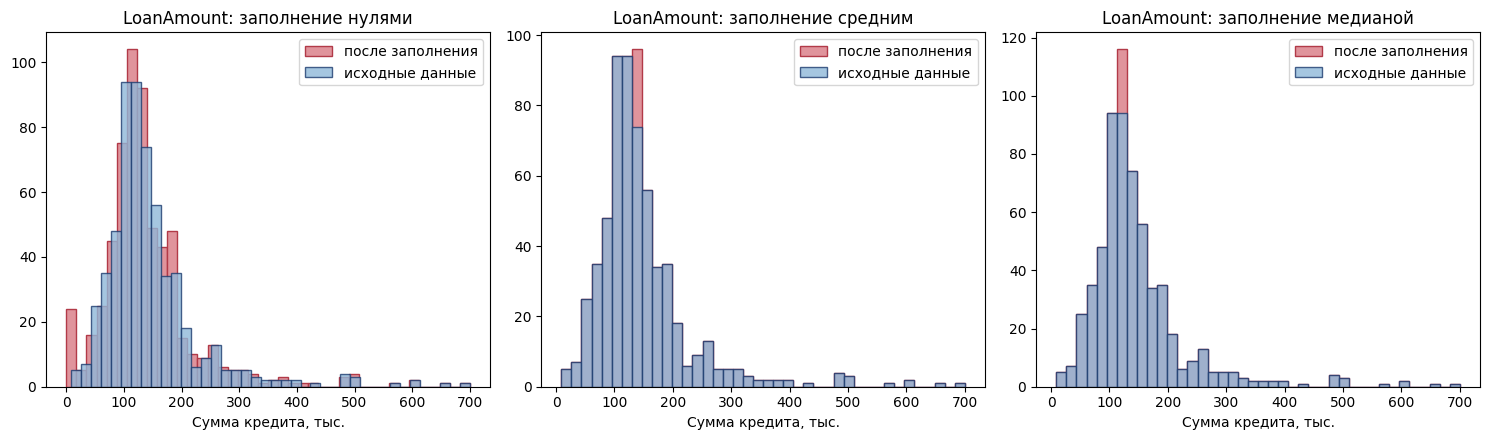

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
variants = [("заполнение нулями", loan_zero), ("заполнение средним", loan_mean),
            ("заполнение медианой", loan_median)]
for ax, (name, s) in zip(axes, variants):
    ax.hist(s, bins=40, color=RED_LIGHT, edgecolor=RED, label="после заполнения")
    ax.hist(df["LoanAmount"].dropna(), bins=40, color=BLUE_LIGHT, edgecolor=BLUE_DARK,
            alpha=0.8, label="исходные данные")
    ax.set_title("LoanAmount: " + name)
    ax.set_xlabel("Сумма кредита, тыс.")
    ax.legend()
plt.tight_layout()
plt.show()


Заполнение нулями даёт заметный выброс около 0 (кредита на 0 не бывает), поэтому этот вариант не подходит. Распределение суммы кредита скошено вправо (есть очень крупные кредиты), поэтому среднее больше медианы. Для `LoanAmount` выбираем **медиану** — она устойчива к выбросам.

Теперь сделаем то же самое через `SimpleImputer` из sklearn. Для `Loan_Amount_Term` (срок кредита) и `Credit_History` значений мало и они повторяются, поэтому для них берём **моду** (самое частое значение).


In [10]:
print("Значения Loan_Amount_Term:")
print(df["Loan_Amount_Term"].value_counts(dropna=False).head(6))
print()
print("Значения Credit_History:")
print(df["Credit_History"].value_counts(dropna=False))


Значения Loan_Amount_Term:
Loan_Amount_Term
360.0    512
180.0     44
480.0     15
NaN       14
300.0     13
240.0      4
Name: count, dtype: int64

Значения Credit_History:
Credit_History
1.0    475
0.0     89
NaN     50
Name: count, dtype: int64


In [11]:
# индикатор пропусков - запомним, в каких строках были пропуски
indicator = MissingIndicator()
mask = indicator.fit_transform(df[num_cols_na])
print("Пропуски по столбцам (из MissingIndicator):",
      dict(zip(num_cols_na, mask.sum(axis=0).tolist())))

df_filled = df.copy()

imp_median = SimpleImputer(strategy="median")
df_filled[["LoanAmount"]] = imp_median.fit_transform(df_filled[["LoanAmount"]])

imp_mode = SimpleImputer(strategy="most_frequent")
df_filled[["Loan_Amount_Term", "Credit_History"]] = imp_mode.fit_transform(
    df_filled[["Loan_Amount_Term", "Credit_History"]])

print("Медиана, которой заполнили LoanAmount:", imp_median.statistics_)
print("Мода для Loan_Amount_Term и Credit_History:", imp_mode.statistics_)
print()
print(df_filled[num_cols_na].isnull().sum())


Пропуски по столбцам (из MissingIndicator): {'LoanAmount': 22, 'Loan_Amount_Term': 14, 'Credit_History': 50}
Медиана, которой заполнили LoanAmount: [128.]
Мода для Loan_Amount_Term и Credit_History: [360.   1.]

LoanAmount          0
Loan_Amount_Term    0
Credit_History      0
dtype: int64


### 3.4. Заполнение пропусков в категориальных признаках

Для категориальных признаков есть два основных варианта: заполнить самым частым значением (модой) или ввести отдельную категорию, например `"NA"`.


In [12]:
for col in cat_cols_na:
    print(col, df[col].value_counts(dropna=False).to_dict())


Gender {'Male': 489, 'Female': 112, nan: 13}
Married {'Yes': 398, 'No': 213, nan: 3}
Dependents {'0': 345, '1': 102, '2': 101, '3+': 51, nan: 15}
Self_Employed {'No': 500, 'Yes': 82, nan: 32}


In [13]:
# вариант 1 - отдельная категория "NA"
imp_const = SimpleImputer(strategy="constant", fill_value="NA")
self_emp_const = imp_const.fit_transform(df[["Self_Employed"]])
print("Self_Employed, заполнение константой:")
print(pd.Series(self_emp_const.ravel()).value_counts())


Self_Employed, заполнение константой:
No     500
Yes     82
NA      32
Name: count, dtype: int64


In [14]:
# вариант 2 - мода (его и оставляем: пропусков немного, до 5%)
imp_cat = SimpleImputer(strategy="most_frequent")
df_filled[cat_cols_na] = imp_cat.fit_transform(df_filled[cat_cols_na])

print("Мода по столбцам:", dict(zip(cat_cols_na, imp_cat.statistics_)))
print()
for col in cat_cols_na:
    print(col, df_filled[col].value_counts().to_dict())


Мода по столбцам: {'Gender': 'Male', 'Married': 'Yes', 'Dependents': '0', 'Self_Employed': 'No'}

Gender {'Male': 502, 'Female': 112}
Married {'Yes': 401, 'No': 213}
Dependents {'0': 360, '1': 102, '2': 101, '3+': 51}
Self_Employed {'No': 532, 'Yes': 82}


In [15]:
print("Пропусков осталось:", df_filled.isnull().sum().sum())
df_filled.head()


Пропусков осталось: 0


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 4. Кодирование категориальных признаков

Категориальные признаки после заполнения пропусков:


In [16]:
cat_cols = df_filled.select_dtypes(include="object").columns.drop("Loan_ID")
for col in cat_cols:
    print(f"{col:15} {df_filled[col].unique()}")


Gender          ['Male' 'Female']
Married         ['No' 'Yes']
Dependents      ['0' '1' '2' '3+']
Education       ['Graduate' 'Not Graduate']
Self_Employed   ['No' 'Yes']
Property_Area   ['Urban' 'Rural' 'Semiurban']
Loan_Status     ['Y' 'N']


### 4.1. Кодирование целочисленными значениями (LabelEncoder)

Бинарные признаки и целевой признак `Loan_Status` кодируем через `LabelEncoder` — каждой категории присваивается число 0 или 1.


In [17]:
df_enc = df_filled.copy()
binary_cols = ["Gender", "Married", "Education", "Self_Employed", "Loan_Status"]

for col in binary_cols:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col])
    print(f"{col:15}", dict(zip(le.classes_, le.transform(le.classes_).tolist())))


Gender          {'Female': 0, 'Male': 1}
Married         {'No': 0, 'Yes': 1}
Education       {'Graduate': 0, 'Not Graduate': 1}
Self_Employed   {'No': 0, 'Yes': 1}
Loan_Status     {'N': 0, 'Y': 1}


### 4.2. Порядковое кодирование (OrdinalEncoder)

У признака `Dependents` значения упорядочены (0 < 1 < 2 < 3+), поэтому используем `OrdinalEncoder` с явным порядком категорий.


In [18]:
ord_enc = OrdinalEncoder(categories=[["0", "1", "2", "3+"]])
df_enc["Dependents"] = ord_enc.fit_transform(df_enc[["Dependents"]]).astype(int)

pd.concat([df_filled["Dependents"].rename("Dependents (было)"),
           df_enc["Dependents"].rename("Dependents (стало)")], axis=1).drop_duplicates()


,Dependents (было),Dependents (стало)
0,0,0
1,1,1
5,2,2
7,3+,3


### 4.3. One-hot кодирование (OneHotEncoder, get_dummies)

У `Property_Area` три категории без порядка. Если закодировать их числами 0, 1, 2, модель решит, что Urban «больше» Rural. Поэтому используем one-hot кодирование: для каждой категории — отдельный столбец 0/1.


In [19]:
ohe = OneHotEncoder()
area_ohe = ohe.fit_transform(df_enc[["Property_Area"]])
print("Категории:", ohe.categories_)
print("Размер разреженной матрицы:", area_ohe.shape)
print(area_ohe.toarray()[:5])


Категории: [array(['Rural', 'Semiurban', 'Urban'], dtype=object)]
Размер разреженной матрицы: (614, 3)
[[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]]


In [20]:
# то же самое через pandas, сразу получаем DataFrame с понятными названиями столбцов
area_dummies = pd.get_dummies(df_enc["Property_Area"], prefix="Area", dtype=int)
df_enc = pd.concat([df_enc.drop(columns=["Property_Area"]), area_dummies], axis=1)
df_enc.head()


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Area_Rural,Area_Semiurban,Area_Urban
0,LP001002,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,1,0,0,1
1,LP001003,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,1,0,0
2,LP001005,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,1,0,0,1
3,LP001006,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,1,0,0,1
4,LP001008,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,1,0,0,1


In [21]:
df_enc.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             614 non-null    int64  
 2   Married            614 non-null    int64  
 3   Dependents         614 non-null    int64  
 4   Education          614 non-null    int64  
 5   Self_Employed      614 non-null    int64  
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   614 non-null    float64
 10  Credit_History     614 non-null    float64
 11  Loan_Status        614 non-null    int64  
 12  Area_Rural         614 non-null    int64  
 13  Area_Semiurban     614 non-null    int64  
 14  Area_Urban         614 non-null    int64  
dtypes: float64(4), int64(10), object(1)
memory usage: 72.1+ KB


Все признаки, кроме `Loan_ID`, стали числовыми, и их можно подавать в модель.

## 5. Масштабирование данных

Денежные признаки сильно различаются по масштабу: доход измеряется тысячами, а сумма кредита — сотнями. Масштабируем `ApplicantIncome`, `CoapplicantIncome` и `LoanAmount`.


In [22]:
scale_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]
df_enc[scale_cols].describe().round(2)


,ApplicantIncome,CoapplicantIncome,LoanAmount
count,614.00,614.00,614.00
mean,5403.46,1621.25,145.75
std,6109.04,2926.25,84.11
min,150.00,0.00,9.00
25%,2877.50,0.00,100.25
50%,3812.50,1188.50,128.00
75%,5795.00,2297.25,164.75
max,81000.00,41667.00,700.00


### 5.1. MinMax-масштабирование

Значения переводятся в диапазон [0, 1]: $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$


In [23]:
mm = MinMaxScaler()
data_mm = pd.DataFrame(mm.fit_transform(df_enc[scale_cols]), columns=scale_cols)
data_mm.describe().round(3)


,ApplicantIncome,CoapplicantIncome,LoanAmount
count,614.000,614.000,614.000
mean,0.065,0.039,0.198
std,0.076,0.070,0.122
min,0.000,0.000,0.000
25%,0.034,0.000,0.132
50%,0.045,0.029,0.172
75%,0.070,0.055,0.225
max,1.000,1.000,1.000


### 5.2. Масштабирование на основе Z-оценки (StandardScaler)

Из значения вычитается среднее и результат делится на стандартное отклонение: $x' = \dfrac{x - \mu}{\sigma}$. После этого среднее равно 0, а стандартное отклонение — 1.


In [24]:
ss = StandardScaler()
data_ss = pd.DataFrame(ss.fit_transform(df_enc[scale_cols]), columns=scale_cols)
data_ss.describe().round(3)


,ApplicantIncome,CoapplicantIncome,LoanAmount
count,614.000,614.000,614.000
mean,-0.000,0.000,-0.000
std,1.001,1.001,1.001
min,-0.861,-0.554,-1.627
25%,-0.414,-0.554,-0.541
50%,-0.261,-0.148,-0.211
75%,0.064,0.231,0.226
max,12.385,13.696,6.595


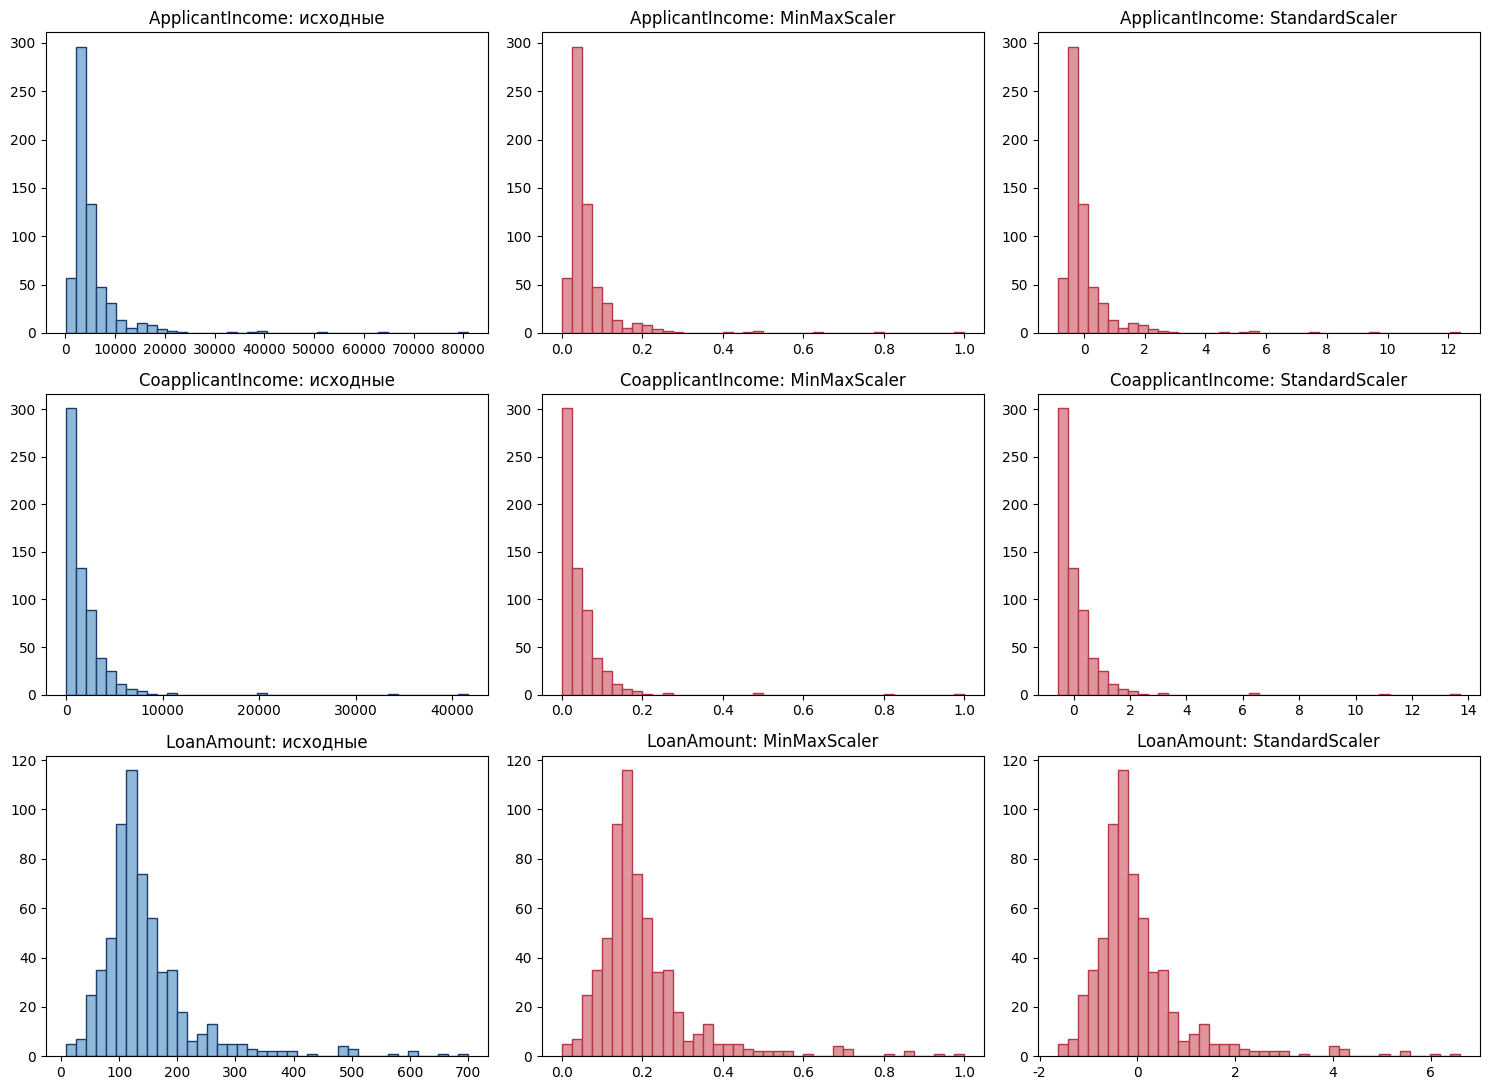

In [25]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
titles = ["исходные", "MinMaxScaler", "StandardScaler"]
colors = [(BLUE_LIGHT, BLUE_DARK), (RED_LIGHT, RED), (RED_LIGHT, RED)]
for i, col in enumerate(scale_cols):
    for j, data in enumerate([df_enc, data_mm, data_ss]):
        ax = axes[i, j]
        ax.hist(data[col], bins=40, color=colors[j][0], edgecolor=colors[j][1])
        ax.set_title(f"{col}: {titles[j]}")
plt.tight_layout()
plt.show()


Форма распределения после масштабирования не изменилась, поменялась только шкала по оси X. У доходов есть сильные выбросы (максимум 81 000 при медиане около 3 800), поэтому после MinMaxScaler почти все значения оказываются около нуля. После StandardScaler выбросы тоже хорошо видны: максимум больше 12 стандартных отклонений.

### 5.3. Нормализация (Normalizer)

`Normalizer` работает не по столбцам, а по строкам: каждая строка делится на свою длину (L2-норму), чтобы длина вектора стала равна 1.


In [26]:
norm = Normalizer()
data_norm = pd.DataFrame(norm.fit_transform(df_enc[scale_cols]), columns=scale_cols)

print("Норма первых 5 строк после нормализации:")
print(np.linalg.norm(data_norm.head().values, axis=1).round(3))
data_norm.head()


Норма первых 5 строк после нормализации:
[1. 1. 1. 1. 1.]


,ApplicantIncome,CoapplicantIncome,LoanAmount
0,0.999761,0.000000,0.021879
1,0.949565,0.312447,0.026521
2,0.999758,0.000000,0.021995
3,0.738107,0.673812,0.034291
4,0.999724,0.000000,0.023494


### 5.4. Итоговый датасет

Для дальнейшего построения моделей берём вариант с StandardScaler.


In [27]:
df_final = df_enc.copy()
df_final[scale_cols] = data_ss.values
df_final.head()


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Area_Rural,Area_Semiurban,Area_Urban
0,LP001002,1,0,0,0,0,0.072991,-0.554487,-0.211241,360.0,1.0,1,0,0,1
1,LP001003,1,1,1,0,0,-0.134412,-0.038732,-0.211241,360.0,1.0,0,1,0,0
2,LP001005,1,1,0,0,1,-0.393747,-0.554487,-0.948996,360.0,1.0,1,0,0,1
3,LP001006,1,1,0,1,0,-0.462062,0.251980,-0.306435,360.0,1.0,1,0,0,1
4,LP001008,1,0,0,0,0,0.097728,-0.554487,-0.056551,360.0,1.0,1,0,0,1


In [28]:
print("Размер:", df_final.shape)
print("Пропусков:", df_final.isnull().sum().sum())
print("Нечисловые столбцы:", list(df_final.select_dtypes(exclude="number").columns))


Размер: (614, 15)
Пропусков: 0
Нечисловые столбцы: ['Loan_ID']


## 6. Выводы

1. Выбран финансовый датасет заявок на кредит (614 записей, 13 признаков). Пропуски есть в 7 столбцах, больше всего — в `Credit_History` (8,1%).
2. Удалять строки с пропусками нецелесообразно: так теряется около 22% данных. Поэтому пропуски заполнили: `LoanAmount` — медианой, потому что распределение скошено; `Loan_Amount_Term`, `Credit_History` и категориальные признаки — модой.
3. Категориальные признаки закодированы: бинарные и целевой — через LabelEncoder, порядковый `Dependents` — через OrdinalEncoder, `Property_Area` — one-hot кодированием.
4. Денежные признаки отмасштабированы MinMaxScaler и StandardScaler, также показана построчная нормализация (Normalizer). Масштабирование не меняет форму распределения, а только переводит признаки в одну шкалу.
5. В итоге получен полностью числовой датасет без пропусков, который можно использовать для обучения моделей.
